# MIT 6.7920 — Homework 7: REINFORCE with CartPole

**Student starter** · Fall 2026

Implement REINFORCE, compare return estimators and a learned value baseline, then compare with a hand-designed controller and a linear policy.

**Submission:** Include your figures, numerical results, and written answers in a PDF on Gradescope. Submit a link to your own copy of this Colab notebook with **Viewer** access to course staff. Do not edit the instructor's shared template. Results may vary with random seeds; explain what your data actually shows.


## Setup

Run this cell in Google Colab. This notebook uses **Gymnasium** (the maintained Gym API), PyTorch and `CartPole-v1`. It needs no GPU or virtual display. All videos use `render_mode='rgb_array'`.


In [1]:
%pip -q install 'gymnasium[classic-control]>=1.0,<2' 'imageio[ffmpeg]'

import random
from pathlib import Path
import numpy as np
import matplotlib.pyplot as plt
import torch
from torch import nn
import torch.nn.functional as F
from torch.distributions import Categorical
import gymnasium as gym
from gymnasium.wrappers import RecordVideo
from IPython.display import Video, display

DEVICE = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
TASK = 'CartPole-v1'

def set_seed(seed):
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)

def show_video(folder):
    paths = sorted(Path(folder).glob('*.mp4'))
    if paths:
        display(Video(str(paths[-1]), embed=True))
    else:
        print('No video was produced.')

print('Gymnasium', gym.__version__, '| Torch', torch.__version__, '| Device', DEVICE)


Gymnasium 1.4.0 | Torch 2.15.0 | Device cpu


### Environment demonstration

`reset()` returns `(observation, info)`. `step()` returns `(observation, reward, terminated, truncated, info)`. Stop if **either** `terminated` or `truncated` is true. A 500-step CartPole time limit is truncation, not failure termination.


In [2]:
demo_env = gym.make(TASK, render_mode='rgb_array')
demo_env = RecordVideo(demo_env, video_folder='videos/random', episode_trigger=lambda _: True)
obs, info = demo_env.reset(seed=0)
print('Observation space:', demo_env.observation_space)
print('Action space:', demo_env.action_space)
done = False
while not done:
    obs, reward, terminated, truncated, info = demo_env.step(demo_env.action_space.sample())
    done = terminated or truncated
demo_env.close()
show_video('videos/random')


Observation space: Box([-4.8               -inf -0.41887903        -inf], [4.8               inf 0.41887903        inf], (4,), float32)
Action space: Discrete(2)


## REINFORCE objectives

For an episode of length $T$ (time indices $0,\ldots,T-1$), let

$$R=\sum_{t=0}^{T-1}\gamma^t r_t,\qquad G_t=\sum_{k=t}^{T-1}\gamma^{k-t}r_k.$$

The Monte Carlo **gradient estimators** (not the value function itself) are:

- **Vanilla:** $\widehat g=R\sum_t\nabla_\theta\log\pi_\theta(a_t\mid s_t)$.
- **Temporal/reward-to-go:** $\widehat g=\sum_t\gamma^tG_t\nabla_\theta\log\pi_\theta(a_t\mid s_t)$.
- **Temporal + baseline:** $\widehat g=\sum_t\gamma^t(G_t-V_\phi(s_t))\nabla_\theta\log\pi_\theta(a_t\mid s_t)$.

Train by minimizing the negative Monte Carlo policy-gradient surrogate. Fit the baseline with regression to $G_t$; **detach it in the policy loss**. Using a value baseline does not turn this implementation into TD actor-critic: the target remains a full Monte Carlo return.


## Part 1 — Policy and value networks

Complete `PGNetwork` and `ValueNetwork`. For a non-linear policy, use two fully connected hidden layers of width 64 and ReLU; for `layers=0`, use an affine map from four observations to two logits. The policy returns a `torch.distributions.Categorical` object. The value network returns one scalar per observation, shape `(batch,)`.


In [3]:
class PGNetwork(nn.Module):
    def __init__(self, in_dim=4, out_dim=2, hidden_dim=64, layers=2):
        super().__init__()
        if layers == 0:                       # affine policy: logits = W s + b
            self.net = nn.Linear(in_dim, out_dim)
        else:                                 # MLP with `layers` hidden ReLU layers
            mods, d = [], in_dim
            for _ in range(layers):
                mods += [nn.Linear(d, hidden_dim), nn.ReLU()]
                d = hidden_dim
            mods.append(nn.Linear(d, out_dim))
            self.net = nn.Sequential(*mods)

    def forward(self, observations):
        return Categorical(logits=self.net(observations))


class ValueNetwork(nn.Module):
    def __init__(self, in_dim=4, hidden_dim=64):
        super().__init__()
        self.net = nn.Sequential(
            nn.Linear(in_dim, hidden_dim), nn.ReLU(),
            nn.Linear(hidden_dim, hidden_dim), nn.ReLU(),
            nn.Linear(hidden_dim, 1))

    def forward(self, observations):
        return self.net(observations).squeeze(-1)          # shape (batch,)


## Part 2 — Rollout and gradient update

The `rollout` helper owns no global environment. It records log probabilities and, when supplied, differentiable value estimates. Complete `discounted_returns()` and `update_parameters()` below. Use the supplied optimizer to update both networks when a baseline is present.


In [4]:
def rollout(env, policy, value_net=None, device=DEVICE, max_steps=500, seed=None):
    obs, info = env.reset(seed=seed)
    rewards, log_probs, values = [], [], []
    for _ in range(max_steps):
        state = torch.as_tensor(obs, dtype=torch.float32, device=device).unsqueeze(0)
        distribution = policy(state)
        action = distribution.sample()
        log_probs.append(distribution.log_prob(action).squeeze(0))
        if value_net is not None:
            values.append(value_net(state).squeeze(0))
        obs, reward, terminated, truncated, info = env.step(int(action.item()))
        rewards.append(float(reward))
        if terminated or truncated:
            break
    rewards = torch.tensor(rewards, dtype=torch.float32, device=device)
    log_probs = torch.stack(log_probs)
    values = torch.stack(values) if value_net is not None else None
    return rewards, log_probs, values


In [5]:
def discounted_returns(rewards, gamma):
    """G_t = r_t + gamma G_{t+1}, computed backwards (G_T = 0)."""
    G = torch.zeros_like(rewards)
    running = 0.0
    for t in reversed(range(len(rewards))):
        running = rewards[t] + gamma * running
        G[t] = running
    return G


def update_parameters(optimizer, rewards, log_probs, gamma,
                      values=None, temporal=True):
    G = discounted_returns(rewards, gamma)
    discounts = gamma ** torch.arange(len(rewards), dtype=torch.float32, device=rewards.device)
    if temporal:
        # sum_t gamma^t (G_t - b(s_t)) grad log pi(a_t|s_t)
        advantage = G - values.detach() if values is not None else G
        policy_loss = -(discounts * advantage * log_probs).sum()
    else:
        # R * sum_t grad log pi(a_t|s_t),  R = G_0
        policy_loss = -(G[0] * log_probs.sum())
    value_loss = F.smooth_l1_loss(values, G) if values is not None else torch.zeros((), device=rewards.device)
    optimizer.zero_grad()
    (policy_loss + value_loss).backward()
    optimizer.step()
    return policy_loss.item(), value_loss.item()


## Training and evaluation helpers

`train()` creates and closes its own environment, records an exponential moving average (EMA) of episode rewards, and returns both the reward history and policy. `evaluate()` uses a separate environment and reports performance over multiple episodes. For reproducibility, pass seeds explicitly. The evaluation defaults to stochastic sampling, consistent with the trained policy; greedy evaluation is available for visualization only.


In [6]:
def train(seed=0, episodes=600, lr=1e-3, gamma=0.999,
          layers=2, temporal=True, baseline=False, verbose=False):
    set_seed(seed)
    env = gym.make(TASK)
    env.action_space.seed(seed)
    policy = PGNetwork(layers=layers).to(DEVICE)
    value_net = ValueNetwork().to(DEVICE) if baseline else None
    params = list(policy.parameters())
    if baseline:
        params += list(value_net.parameters())
    optimizer = torch.optim.Adam(params, lr=lr)
    episode_rewards, moving_rewards = [], []
    ema = None
    try:
        for episode in range(episodes):
            rewards, log_probs, values = rollout(
                env, policy, value_net=value_net, seed=seed if episode == 0 else None)
            reward = float(rewards.sum().item())
            episode_rewards.append(reward)
            ema = reward if ema is None else 0.05 * reward + 0.95 * ema
            moving_rewards.append(ema)
            update_parameters(optimizer, rewards, log_probs, gamma,
                              values=values, temporal=temporal)
            if verbose and (episode + 1) % 100 == 0:
                print(f'Episode {episode+1}: reward={reward:.0f}, EMA={ema:.1f}')
    finally:
        env.close()
    return {'policy': policy, 'value_net': value_net,
            'episode_rewards': np.array(episode_rewards),
            'ema_rewards': np.array(moving_rewards)}


@torch.no_grad()
def evaluate(policy, episodes=20, seed=1000, greedy=False):
    env = gym.make(TASK)
    policy.eval()
    results = []
    try:
        for i in range(episodes):
            obs, info = env.reset(seed=seed+i)
            done, total = False, 0.0
            while not done:
                x = torch.as_tensor(obs, dtype=torch.float32, device=DEVICE).unsqueeze(0)
                dist = policy(x)
                action = dist.probs.argmax(dim=-1) if greedy else dist.sample()
                obs, reward, terminated, truncated, info = env.step(int(action.item()))
                total += reward
                done = terminated or truncated
            results.append(total)
    finally:
        env.close()
    policy.train()
    return np.array(results)


@torch.no_grad()
def visualize_policy(policy, folder='videos/policy', greedy=True, seed=2026):
    env = gym.make(TASK, render_mode='rgb_array')
    env = RecordVideo(env, video_folder=folder, episode_trigger=lambda _: True)
    obs, info = env.reset(seed=seed)
    done, total = False, 0
    while not done:
        x = torch.as_tensor(obs, dtype=torch.float32, device=DEVICE).unsqueeze(0)
        dist = policy(x)
        a = dist.probs.argmax(dim=-1) if greedy else dist.sample()
        obs, reward, terminated, truncated, info = env.step(int(a.item()))
        total += reward
        done = terminated or truncated
    env.close()
    print('Video episode reward:', total, '(greedy)' if greedy else '(sampled)')
    show_video(folder)


## (a) Vanilla vs. temporal REINFORCE

Train the same two-hidden-layer policy **without a baseline** using both estimators. Report training curves and evaluation rewards. Which seems to converge faster? Explain why the reward-to-go estimator removes irrelevant past rewards. A single run is illustrative, not definitive.


vanilla   seed 0: final EMA= 138.7 | eval (sampled)  121.6 +-  30.8 | eval (greedy)  127.7


vanilla   seed 1: final EMA= 107.2 | eval (sampled)  122.5 +-  37.8 | eval (greedy)  319.2


vanilla   seed 2: final EMA=  86.7 | eval (sampled)   72.8 +-  37.7 | eval (greedy)  258.7
vanilla   seed 3: final EMA= 138.0 | eval (sampled)   81.2 +-  40.6 | eval (greedy)   95.7


vanilla   seed 4: final EMA= 119.3 | eval (sampled)  163.3 +-  44.5 | eval (greedy)  220.8


temporal  seed 0: final EMA= 377.0 | eval (sampled)  395.9 +- 109.9 | eval (greedy)  500.0


temporal  seed 1: final EMA= 148.3 | eval (sampled)  144.3 +-  53.0 | eval (greedy)  177.3


temporal  seed 2: final EMA= 328.3 | eval (sampled)  174.2 +-  40.1 | eval (greedy)  190.6


temporal  seed 3: final EMA= 426.8 | eval (sampled)  439.4 +- 114.3 | eval (greedy)  500.0


temporal  seed 4: final EMA= 136.3 | eval (sampled)  174.5 +-  21.9 | eval (greedy)  199.9


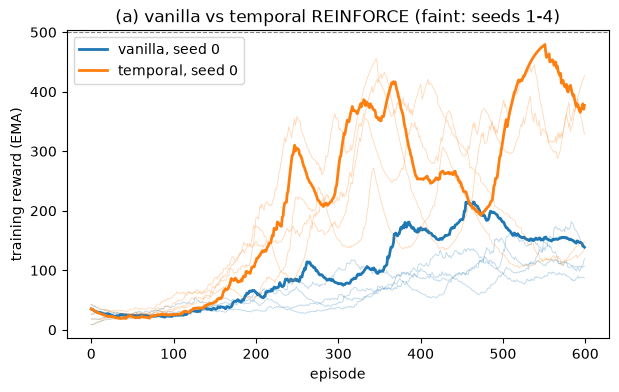

In [7]:
### (a) vanilla vs temporal REINFORCE, same 2-layer policy, no baseline
SEEDS = [0, 1, 2, 3, 4]
runs = {}       # runs[name] = list of train() outputs, one per seed (reused in (b) and (d))
runs['vanilla'] = [train(seed=s, temporal=False) for s in SEEDS]
runs['temporal'] = [train(seed=s, temporal=True) for s in SEEDS]

for name in ['vanilla', 'temporal']:
    for s, r in zip(SEEDS, runs[name]):
        ev, gr = evaluate(r['policy']), evaluate(r['policy'], greedy=True)
        print(f"{name:9s} seed {s}: final EMA={r['ema_rewards'][-1]:6.1f} | "
              f"eval (sampled) {ev.mean():6.1f} +- {ev.std():5.1f} | eval (greedy) {gr.mean():6.1f}")

fig, ax = plt.subplots(figsize=(7, 4))
for name, col in [('vanilla', 'C0'), ('temporal', 'C1')]:
    for s, r in zip(SEEDS, runs[name]):
        ax.plot(r['ema_rewards'], color=col, lw=2 if s == 0 else 0.6, alpha=1 if s == 0 else 0.3,
                label=f'{name}, seed 0' if s == 0 else None)
ax.axhline(500, color='gray', ls='--', lw=0.8)
ax.set_xlabel('episode'); ax.set_ylabel('training reward (EMA)')
ax.set_title('(a) vanilla vs temporal REINFORCE (faint: seeds 1-4)'); ax.legend()
plt.show()


**Your answer:** Temporal converges much faster. With seed 0 its EMA reaches 400 at episode 363 and it evals at 395.9 (500 greedy), while vanilla ends at an EMA of 138.7 and evals at 121.6. The other seeds agree (mean eval 265.7 vs. 112.3).

A reward $r_k$ with $k<t$ is received before $a_t$ is chosen, so $\mathbb E[r_k\nabla_\theta\log\pi_\theta(a_t\mid s_t)]=0$. These terms only add variance, and reward-to-go removes them: each action is only credited with the rewards that came after it.

## (b) Effect of a value-function baseline

Use temporal REINFORCE with and without a learned baseline. Plot the mean training-reward EMA across **at least 3 independent seeds** for each method, preferably with a variability band. Compare convergence and robustness. The baseline may improve performance, but improvement is not guaranteed for every seed.


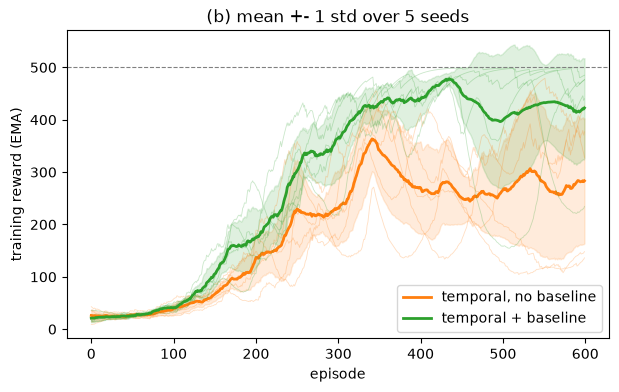

temporal  eval per seed [394.2 139.2 169.4 467.  177.6] (mean 269.5) | final EMA 283.3 +- 119.4 | first episode EMA>=400: [363, 332, 341, 594, None]


baseline  eval per seed [260.4 475.4 445.2 500.  500. ] (mean 436.2) | final EMA 422.5 +- 95.3 | first episode EMA>=400: [277, 247, 362, 329, 311]


In [8]:
### (b) temporal REINFORCE with and without a learned value baseline, 5 seeds
runs['baseline'] = [train(seed=s, temporal=True, baseline=True) for s in SEEDS]

def plot_band(ax, rs, color, label):
    E = np.stack([r['ema_rewards'] for r in rs])
    m, sd = E.mean(0), E.std(0)
    for e in E:
        ax.plot(e, color=color, lw=0.6, alpha=0.25)
    ax.fill_between(np.arange(len(m)), m - sd, m + sd, color=color, alpha=0.15)
    ax.plot(m, color=color, lw=2, label=label)

def first_episode(ema, thr):
    idx = np.flatnonzero(ema >= thr)
    return int(idx[0]) + 1 if len(idx) else None

fig, ax = plt.subplots(figsize=(7, 4))
plot_band(ax, runs['temporal'], 'C1', 'temporal, no baseline')
plot_band(ax, runs['baseline'], 'C2', 'temporal + baseline')
ax.axhline(500, color='gray', ls='--', lw=0.8)
ax.set_xlabel('episode'); ax.set_ylabel('training reward (EMA)')
ax.set_title('(b) mean +- 1 std over 5 seeds'); ax.legend(); plt.show()

for name in ['temporal', 'baseline']:
    ev = np.array([evaluate(r['policy']).mean() for r in runs[name]])
    end = np.array([r['ema_rewards'][-1] for r in runs[name]])
    print(f"{name:9s} eval per seed {np.round(ev, 1)} (mean {ev.mean():.1f}) | final EMA {end.mean():.1f} +- {end.std():.1f}"
          f" | first episode EMA>=400: {[first_episode(r['ema_rewards'], 400) for r in runs[name]]}")


**Your answer:** The baseline converges faster and is more robust. Its final EMA is $422.5\pm95.3$ vs. $283.3\pm119.4$, its mean eval is 436.2 vs. 269.5, and its EMA reaches 400 on 5/5 seeds vs. 4/5. Without it, runs tend to peak and then collapse. The improvement is not guaranteed though: baseline seed 0 only evals at 260.4.

Since $V_\phi(s_t)$ does not depend on $a_t$, it does not change the expected gradient. But here every $G_t>0$, so without a baseline every sampled action is pushed up. Subtracting $V_\phi(s_t)$ centers the weights and reduces the variance.

## (c) Hand-designed controller

Implement the deterministic policy $a=1$ if $3\theta+\dot\theta>0$, and $a=0$ otherwise. Evaluate it over several episode starts. Explain why it works and where it can fail (consider cart position and velocity).


In [9]:
def hand_designed_policy(obs):
    # obs = (cart position, cart velocity, pole angle, angular velocity)
    x, x_dot, theta, theta_dot = obs
    return int(3 * theta + theta_dot > 0)


In [10]:
def evaluate_hand_designed(episodes=20, seed=1000):
    env = gym.make(TASK)
    results = []
    try:
        for i in range(episodes):
            obs, info = env.reset(seed=seed+i)
            total, done = 0, False
            while not done:
                obs, reward, terminated, truncated, info = env.step(hand_designed_policy(obs))
                total += reward
                done = terminated or truncated
            results.append(total)
    finally:
        env.close()
    return np.array(results)

hand_scores = evaluate_hand_designed()
print(f'Hand-designed: mean={hand_scores.mean():.1f}, std={hand_scores.std():.1f}')


Hand-designed: mean=500.0, std=0.0


200 starts, no 500-step limit: {'cart position': 161, 'survived 10k': 39} | median length 3132.5
initial cart velocity 0.0: survives 500 steps (final x = 0.00)
initial cart velocity 0.5: survives 240 steps (final x = 2.40)
initial cart velocity 1.0: survives 120 steps (final x = 2.40)
initial cart velocity 1.5: survives 81 steps (final x = 2.43)
initial cart velocity 2.0: survives 61 steps (final x = 2.44)


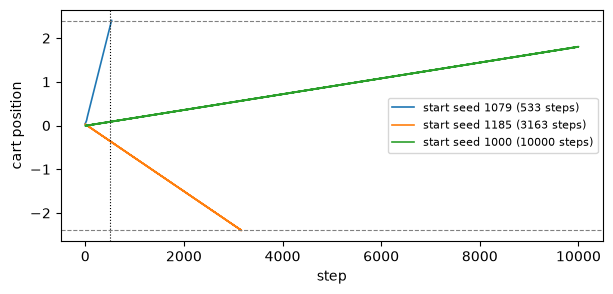

In [11]:
### (c) where the hand-designed controller fails: remove the 500-step limit, and give the cart an initial velocity
env = gym.make(TASK, max_episode_steps=10_000)
lengths, causes, trajs = [], [], {}
for i in range(200):
    obs, _ = env.reset(seed=1000 + i)
    xs, done = [obs[0]], False
    while not done:
        obs, r, term, trunc, _ = env.step(hand_designed_policy(obs))
        xs.append(obs[0]); done = term or trunc
    lengths.append(len(xs) - 1); trajs[1000 + i] = xs
    causes.append('cart position' if abs(obs[0]) > 2.4 else ('pole angle' if abs(obs[2]) > 0.2095 else 'survived 10k'))
lengths = np.array(lengths)
print('200 starts, no 500-step limit:', {c: causes.count(c) for c in set(causes)}, '| median length', np.median(lengths))

for v0 in [0.0, 0.5, 1.0, 1.5, 2.0]:
    env.reset(seed=2000)
    env.unwrapped.state = np.array([0.0, v0, 0.0, 0.0])      # upright pole, cart moving at v0
    obs, t, done = np.array(env.unwrapped.state, dtype=np.float32), 0, False
    while not done and t < 500:
        obs, r, term, trunc, _ = env.step(hand_designed_policy(obs)); t += 1; done = term or trunc
    print(f'initial cart velocity {v0}: survives {t} steps (final x = {obs[0]:.2f})')
env.close()

fig, ax = plt.subplots(figsize=(7, 3))
for s in [1000 + int(np.argmin(lengths)), 1000 + int(np.argsort(lengths)[100]), 1000]:
    ax.plot(trajs[s], lw=1.2, label=f'start seed {s} ({len(trajs[s]) - 1} steps)')
for y in (-2.4, 2.4):
    ax.axhline(y, color='gray', ls='--', lw=0.8)
ax.axvline(500, color='k', ls=':', lw=0.8)
ax.set_xlabel('step'); ax.set_ylabel('cart position'); ax.legend(fontsize=8); plt.show()


**Your answer:** The controller scores $500\pm0$. $\theta+\dot\theta/3$ is roughly the pole angle $1/3$ s ahead, so it pushes the cart toward the side the pole is falling to, moving it back under the pole.

It fails because it ignores $x$ and $\dot x$, so the cart drifts. Without the 500-step limit, 161 of 200 starts end with the cart off the track (median 3132 steps). If the cart starts with velocity $0.5$, it leaves the track at step 240.

## (d) Learned linear policy

Set `layers=0` so the network has just one affine layer, producing two logits:

$$z_0=w_0^\top s+b_0,\qquad z_1=w_1^\top s+b_1.$$

Train the linear policy with temporal REINFORCE, try **at least two learning rates**, and compare its evaluation performance with the two-layer policy from (b). Report the number of trainable parameters. To compare its decision boundary with the hand-designed controller $[0,0,3,1]^\top$, use the **effective** weight vector $w_1-w_0$ and bias $b_1-b_0$ (not either row separately). Because the hard threshold is scale-invariant, compare normalized weight directions rather than absolute magnitudes.


parameters: linear 10 | MLP 4610

lr=0.001: mean eval 42.3
   w1-w0 = [-0.188 -0.145  0.93   1.262], b1-b0 = 0.002, cos to [0,0,3,1] = 0.808
   w1-w0 = [-1.157  0.03   0.569  0.588], b1-b0 = -0.042, cos to [0,0,3,1] = 0.512
   w1-w0 = [-0.148 -0.25   0.22   0.156], b1-b0 = -0.209, cos to [0,0,3,1] = 0.651
   w1-w0 = [ 0.324 -0.145  1.053  1.19 ], b1-b0 = 0.038, cos to [0,0,3,1] = 0.845
   w1-w0 = [-0.554 -0.554  1.577  1.235], b1-b0 = 0.074, cos to [0,0,3,1] = 0.877



lr=0.01: mean eval 462.6
   w1-w0 = [0.321 1.451 7.706 4.107], b1-b0 = -0.076, cos to [0,0,3,1] = 0.972
   w1-w0 = [0.127 0.777 7.563 3.996], b1-b0 = -0.053, cos to [0,0,3,1] = 0.982
   w1-w0 = [0.516 1.48  8.769 3.54 ], b1-b0 = 0.066, cos to [0,0,3,1] = 0.985
   w1-w0 = [0.176 0.678 7.086 4.456], b1-b0 = 0.104, cos to [0,0,3,1] = 0.968
   w1-w0 = [-0.011  1.103  7.767  3.692], b1-b0 = 0.121, cos to [0,0,3,1] = 0.985



lr=0.03: mean eval 446.7
   w1-w0 = [ 0.745  1.637 12.647  5.498], b1-b0 = -1.286, cos to [0,0,3,1] = 0.988
   w1-w0 = [ 1.667  2.262 13.507  4.596], b1-b0 = 0.587, cos to [0,0,3,1] = 0.981
   w1-w0 = [ 0.806  1.555 15.042  5.336], b1-b0 = -1.496, cos to [0,0,3,1] = 0.994
   w1-w0 = [-0.099  1.979 12.232  4.696], b1-b0 = -0.774, cos to [0,0,3,1] = 0.988
   w1-w0 = [ 1.169  2.459 14.026  4.373], b1-b0 = -1.118, cos to [0,0,3,1] = 0.983


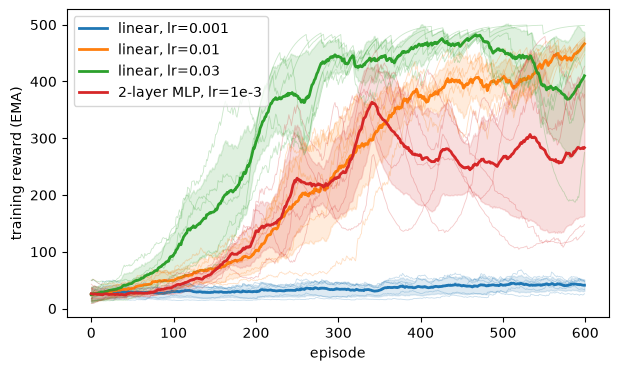

In [12]:
### (d) linear policy (layers=0), temporal REINFORCE, three learning rates
lin = {lr: [train(seed=s, layers=0, lr=lr) for s in SEEDS] for lr in [1e-3, 1e-2, 3e-2]}
count = lambda m: sum(p.numel() for p in m.parameters())
print('parameters: linear', count(PGNetwork(layers=0)), '| MLP', count(PGNetwork(layers=2)))

hand = np.array([0, 0, 3, 1]) / np.sqrt(10)
for lr, rs in lin.items():
    print(f"\nlr={lr:g}: mean eval {np.mean([evaluate(r['policy']).mean() for r in rs]):.1f}")
    for r in rs:
        W, b = r['policy'].net.weight.detach().cpu().numpy(), r['policy'].net.bias.detach().cpu().numpy()
        w, b = W[1] - W[0], b[1] - b[0]
        print(f'   w1-w0 = {np.round(w, 3)}, b1-b0 = {b:.3f}, cos to [0,0,3,1] = {w @ hand / np.linalg.norm(w):.3f}')

fig, ax = plt.subplots(figsize=(7, 4))
for (lr, rs), c in zip(lin.items(), ['C0', 'C1', 'C2']):
    plot_band(ax, rs, c, f'linear, lr={lr:g}')
plot_band(ax, runs['temporal'], 'C3', '2-layer MLP, lr=1e-3')
ax.set_xlabel('episode'); ax.set_ylabel('training reward (EMA)'); ax.legend(); plt.show()


**Your answer:** The linear policy has 10 parameters vs. 4610 for the MLP. Its mean eval is 42.3 at lr $10^{-3}$, 462.6 at lr $10^{-2}$ and 446.7 at lr $3\cdot10^{-2}$, vs. 269.5 for the MLP (436.2 with a baseline). lr $10^{-3}$ is too slow for the linear policy, $10^{-2}$ is the most consistent, and $3\cdot10^{-2}$ is the fastest but less stable. Note that we did not tune the MLP's learning rate.

For seed 0 at lr $10^{-2}$, $w_1-w_0=[0.32,1.45,7.71,4.11]$ and $b_1-b_0=-0.08$. Its cosine similarity with the hand-designed $[0,0,3,1]$ is 0.97, and 0.97–0.99 across seeds. So it learns the same angle rule, plus small positive weights on $x$ and $\dot x$, which is exactly what the hand-designed rule is missing.

## Final checklist

- [ ] Networks and gradients implemented; notebook runs from top to bottom.
- [ ] (a) Training curves and numerical evaluation plus explanation.
- [ ] (b) At least 3 seeds and an appropriate variability visualization.
- [ ] (c) Controller evaluation and limitations.
- [ ] (d) Learning-rate comparison, parameter count, effective coefficients.
- [ ] All plots/results and text included in Gradescope PDF; own Colab link shared with staff as Viewer.

**Reproducibility:** Report package versions, seeds, episode counts, and any changed hyperparameters. Videos illustrate behavior but do not substitute for quantitative evaluation.
